In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/ffzs/dataset/master/Mall_Customers.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())


Dataset loaded successfully!
Dataset shape: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']


In [4]:

import requests

response = requests.get(url, timeout=20)

print("HTTP status:", response.status_code)
print("Response preview:", response.text[:200])


HTTP status: 200
Response preview: CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
1,Male,19,15,39
2,Male,21,15,81
3,Female,20,16,6
4,Female,23,16,77
5,Female,31,17,40
6,Female,22,17,76
7,Female,35,18,6
8,Female,23,18,9


In [5]:

# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Check column names and data types
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Summary statistics
print("\nSummary statistics:")
display(df.describe(include="all").T)

# Check unique values in categorical columns
print("\nGender categories:")
print(df["Gender"].unique())


Number of rows and columns: (200, 5)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate rows: 0

Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,200.0,NaN,NaN,NaN,100.5,57.879185,1.0,50.75,100.5,150.25,200.0
Gender,200,2,Female,112,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,200.0,NaN,NaN,NaN,38.85,13.969007,18.0,28.75,36.0,49.0,70.0
Annual Income (k$),200.0,NaN,NaN,NaN,60.56,26.264721,15.0,41.5,61.5,78.0,137.0
Spending Score (1-100),200.0,NaN,NaN,NaN,50.2,25.823522,1.0,34.75,50.0,73.0,99.0



Gender categories:
['Male' 'Female']


In [6]:

# Create a copy for analysis
customer_df = df.copy()

# Segment customers by spending score
def classify_customer(score):
    if score >= 70:
        return "High Spender"
    elif score >= 40:
        return "Average Spender"
    else:
        return "Low Spender"

customer_df["Spending Segment"] = (
    customer_df["Spending Score (1-100)"]
    .apply(classify_customer)
)

# Display customers with their segments
display(
    customer_df[
        ["CustomerID", "Age", "Annual Income (k$)",
         "Spending Score (1-100)", "Spending Segment"]
    ].head(10)
)


,CustomerID,Age,Annual Income (k$),Spending Score (1-100),Spending Segment
0,1,19,15,39,Low Spender
1,2,21,15,81,High Spender
2,3,20,16,6,Low Spender
3,4,23,16,77,High Spender
4,5,31,17,40,Average Spender
5,6,22,17,76,High Spender
6,7,35,18,6,Low Spender
7,8,23,18,94,High Spender
8,9,64,19,3,Low Spender
9,10,30,19,72,High Spender


In [7]:

segment_summary = (
    customer_df.groupby("Spending Segment")
    .agg(
        Customer_Count=("CustomerID", "count"),
        Average_Age=("Age", "mean"),
        Average_Income=("Annual Income (k$)", "mean"),
        Average_Spending_Score=("Spending Score (1-100)", "mean")
    )
    .round(2)
    .sort_values("Customer_Count", ascending=False)
)

display(segment_summary)


,Customer_Count,Average_Age,Average_Income,Average_Spending_Score
Spending Segment,,,,
Average Spender,87,41.62,55.40,51.07
Low Spender,59,42.64,64.71,18.80
High Spender,54,30.24,64.33,83.11


In [8]:

# Group customers by annual income and spending score
customer_df["Income Group"] = pd.cut(
    customer_df["Annual Income (k$)"],
    bins=[0, 40, 70, float("inf")],
    labels=["Low Income", "Medium Income", "High Income"]
)

income_spending_summary = (
    customer_df.groupby(
        ["Income Group", "Spending Segment"],
        observed=False
    )
    .size()
    .unstack(fill_value=0)
)

display(income_spending_summary)


Spending Segment,Average Spender,High Spender,Low Spender
Income Group,,,
Low Income,9,19,22
Medium Income,73,2,1
High Income,5,33,36


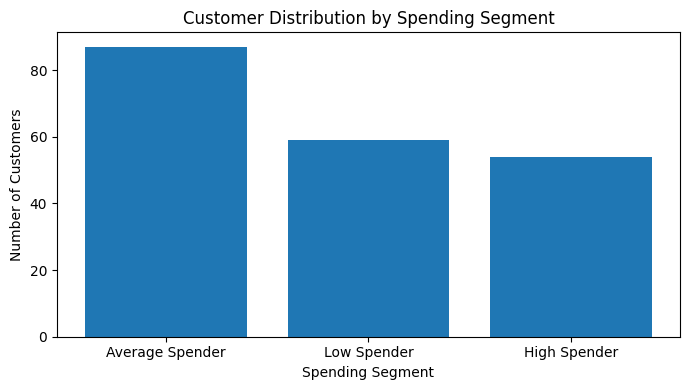

In [9]:

segment_counts = customer_df["Spending Segment"].value_counts()

plt.figure(figsize=(7, 4))
plt.bar(segment_counts.index, segment_counts.values)
plt.title("Customer Distribution by Spending Segment")
plt.xlabel("Spending Segment")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


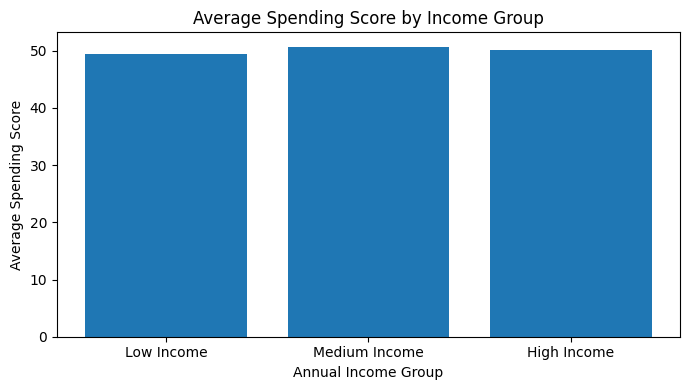

In [10]:

avg_score = customer_df.groupby(
    "Income Group", observed=False
)["Spending Score (1-100)"].mean()

plt.figure(figsize=(7, 4))
plt.bar(avg_score.index.astype(str), avg_score.values)
plt.title("Average Spending Score by Income Group")
plt.xlabel("Annual Income Group")
plt.ylabel("Average Spending Score")
plt.tight_layout()
plt.show()


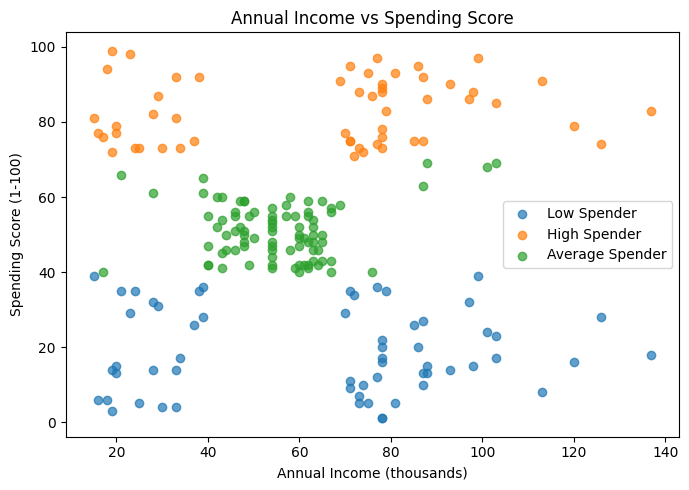

In [11]:

plt.figure(figsize=(7, 5))

for segment in customer_df["Spending Segment"].unique():
    subset = customer_df[
        customer_df["Spending Segment"] == segment
    ]
    plt.scatter(
        subset["Annual Income (k$)"],
        subset["Spending Score (1-100)"],
        label=segment,
        alpha=0.7
    )

plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual Income (thousands)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.tight_layout()
plt.show()


In [12]:

# 1. Customer count by spending segment
print("CUSTOMER DISTRIBUTION")
display(
    customer_df["Spending Segment"]
    .value_counts()
    .rename_axis("Segment")
    .reset_index(name="Customer Count")
)

# 2. Average income and spending score by segment
print("\nSEGMENT PROFILE")
segment_profile = (
    customer_df.groupby("Spending Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Age=("Age", "mean"),
        Avg_Income=("Annual Income (k$)", "mean"),
        Avg_Spending=("Spending Score (1-100)", "mean")
    )
    .round(2)
)
display(segment_profile)

# 3. Highest average spending score
top_segment = segment_profile["Avg_Spending"].idxmax()
print("\nSegment with highest average spending score:", top_segment)

# 4. Highest average annual income
income_segment = segment_profile["Avg_Income"].idxmax()
print("Segment with highest average income:", income_segment)

# 5. Correlation between income and spending score
correlation = customer_df[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].corr().iloc[0, 1]

print("Income-spending score correlation:", round(correlation, 3))


CUSTOMER DISTRIBUTION


,Segment,Customer Count
0,Average Spender,87
1,Low Spender,59
2,High Spender,54



SEGMENT PROFILE


,Customers,Avg_Age,Avg_Income,Avg_Spending
Spending Segment,,,,
Average Spender,87,41.62,55.40,51.07
High Spender,54,30.24,64.33,83.11
Low Spender,59,42.64,64.71,18.80



Segment with highest average spending score: High Spender
Segment with highest average income: Low Spender
Income-spending score correlation: 0.01


In [13]:

recommendations = {
    "High Spender": (
        "Offer loyalty rewards, exclusive benefits, "
        "and personalized premium promotions."
    ),
    "Average Spender": (
        "Use product bundles, cross-selling, and "
        "targeted offers to encourage additional spending."
    ),
    "Low Spender": (
        "Test introductory offers, affordable bundles, "
        "and relevant promotions to encourage engagement."
    )
}

print("MARKETING RECOMMENDATIONS\n")

for segment in ["High Spender", "Average Spender", "Low Spender"]:
    print(segment + ":")
    print(recommendations[segment])
    print()


MARKETING RECOMMENDATIONS

High Spender:
Offer loyalty rewards, exclusive benefits, and personalized premium promotions.

Average Spender:
Use product bundles, cross-selling, and targeted offers to encourage additional spending.

Low Spender:
Test introductory offers, affordable bundles, and relevant promotions to encourage engagement.



In [14]:

# Save segment profile
segment_profile.to_csv("customer_segment_profile.csv")

# Save income group comparison
income_spending_summary.to_csv("customer_income_spending_summary.csv")

# Save recommendations
with open(
    "customer_marketing_recommendations.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write("CUSTOMER ANALYSIS: MARKETING RECOMMENDATIONS\n\n")
    for segment, recommendation in recommendations.items():
        file.write(f"{segment}: {recommendation}\n\n")

print("Customer insights and recommendations saved successfully!")


Customer insights and recommendations saved successfully!


In [15]:

# Step 8: Create a professional customer analysis report

total_customers = len(customer_df)

segment_counts = (
    customer_df["Spending Segment"].value_counts()
)

segment_profile = (
    customer_df.groupby("Spending Segment")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Age=("Age", "mean"),
        Avg_Income=("Annual Income (k$)", "mean"),
        Avg_Spending=("Spending Score (1-100)", "mean")
    )
    .round(2)
)

correlation = customer_df[
    ["Annual Income (k$)", "Spending Score (1-100)"]
].corr().iloc[0, 1]

top_spending_segment = segment_profile["Avg_Spending"].idxmax()
top_income_segment = segment_profile["Avg_Income"].idxmax()
largest_segment = segment_counts.idxmax()

report = f"""
CUSTOMER DATA ANALYSIS
Customer Segmentation and Marketing Recommendations

1. PROJECT OBJECTIVE
Analyze customer characteristics and spending scores to identify
customer segments and propose suitable marketing strategies.

2. DATASET OVERVIEW
Total customer records: {total_customers}
Total columns in original dataset: {df.shape[1]}

Variables analyzed:
- Customer ID
- Gender
- Age
- Annual Income
- Spending Score

3. CUSTOMER SEGMENTATION
Customers were categorized using spending scores:
- High Spender: score >= 70
- Average Spender: score >= 40 and < 70
- Low Spender: score < 40

Customer counts by segment:
{segment_counts.to_string()}

4. SEGMENT PROFILE
Average age, annual income, and spending score by segment:

{segment_profile.to_string()}

Largest segment by customer count: {largest_segment}
Segment with highest average spending score: {top_spending_segment}
Segment with highest average annual income: {top_income_segment}

5. INCOME AND SPENDING RELATIONSHIP
Pearson correlation between annual income and spending score:
{correlation:.3f}

This value describes the linear association in this dataset.
It does not establish a causal relationship.

6. MARKETING RECOMMENDATIONS
High Spender:
Offer loyalty rewards, exclusive benefits, and personalized
premium promotions.

Average Spender:
Test product bundles, cross-selling, and targeted offers.

Low Spender:
Test affordable bundles, introductory offers, and relevant
promotions to encourage engagement.

7. CONCLUSION
Customer segmentation provides a structured way to compare
customers by spending score, age, and annual income. The results
can help guide targeted marketing experiments.

8. LIMITATIONS
The dataset contains customer demographics, annual income, and
spending scores, but not actual transaction histories or revenue.
Therefore, customer lifetime value and actual purchasing behavior
cannot be measured directly from these data.

9. TOOLS USED
Python, Pandas, NumPy, Matplotlib
"""

print(report)

with open(
    "CODSOFT_TASK3_Customer_Analysis_Report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("\nReport saved successfully!")



CUSTOMER DATA ANALYSIS
Customer Segmentation and Marketing Recommendations

1. PROJECT OBJECTIVE
Analyze customer characteristics and spending scores to identify
customer segments and propose suitable marketing strategies.

2. DATASET OVERVIEW
Total customer records: 200
Total columns in original dataset: 5

Variables analyzed:
- Customer ID
- Gender
- Age
- Annual Income
- Spending Score

3. CUSTOMER SEGMENTATION
Customers were categorized using spending scores:
- High Spender: score >= 70
- Average Spender: score >= 40 and < 70
- Low Spender: score < 40

Customer counts by segment:
Spending Segment
Average Spender    87
Low Spender        59
High Spender       54

4. SEGMENT PROFILE
Average age, annual income, and spending score by segment:

                  Customers  Avg_Age  Avg_Income  Avg_Spending
Spending Segment                                              
Average Spender          87    41.62       55.40         51.07
High Spender             54    30.24       64.33        

In [16]:

from google.colab import files

files.download("CODSOFT_TASK3_Customer_Analysis_Report.txt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>